## CL-1 Lab Assignment 1 (Group B): Interacting with Web APIs
### Weather Data Analysis using OpenWeatherMap API

In [1]:
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

In [2]:
# API key
API_KEY = "bf5368148c7573eb0b8c761d051d36e4"

# Cities
cities = ["Pune", "Mumbai", "Delhi", "Bangalore", "Chennai"]
weather_list = []

# Fetch data
for city in cities:
    url = f"https://api.openweathermap.org/data/2.5/weather?q={city}&appid={API_KEY}&units=metric"
    response = requests.get(url, timeout=15)

    if response.status_code == 200:
        data = response.json()
        weather_list.append({
            "City": city,
            "Temperature": data["main"]["temp"],
            "Humidity": data["main"]["humidity"],
            "Wind_Speed": data["wind"]["speed"],
            "Precipitation": data.get("rain", {}).get("1h", 0),
            "Latitude": data["coord"]["lat"],
            "Longitude": data["coord"]["lon"]
        })
    else:
        print("Error retrieving data for", city, response.status_code)

# Create DataFrame
df = pd.DataFrame(weather_list)

# Cleaning
df.fillna(0, inplace=True)

print("\nWeather Data:")
display(df)


Weather Data:


,City,Temperature,Humidity,Wind_Speed,Precipitation,Latitude,Longitude
0,Pune,24.73,54,0.64,0.00,18.5196,73.8553
1,Mumbai,29.50,67,4.28,0.00,19.0144,72.8479
2,Delhi,28.93,53,2.47,0.00,28.6667,77.2167
3,Bangalore,26.92,60,3.16,1.88,12.9762,77.6033
4,Chennai,25.33,94,3.57,0.11,13.0878,80.2785


In [3]:
# Statistics
print("\nAverage Temperature:", df["Temperature"].mean())
print("Maximum Temperature:", df["Temperature"].max())
print("Minimum Temperature:", df["Temperature"].min())

print("\nAverage Humidity:", df["Humidity"].mean())
print("Average Wind Speed:", df["Wind_Speed"].mean())


Average Temperature: 27.082
Maximum Temperature: 29.5
Minimum Temperature: 24.73

Average Humidity: 65.6
Average Wind Speed: 2.8240000000000003


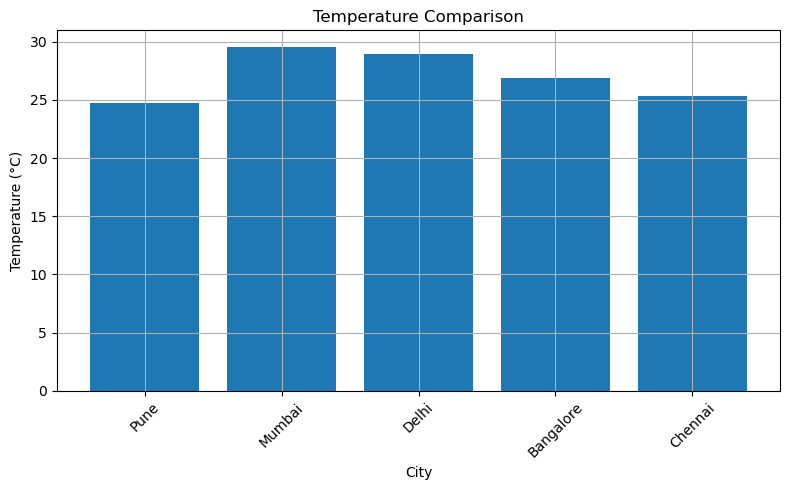

In [4]:
# Temperature visualization
plt.figure(figsize=(8, 5))
plt.bar(df["City"], df["Temperature"])
plt.xlabel("City")
plt.ylabel("Temperature (°C)")
plt.title("Temperature Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

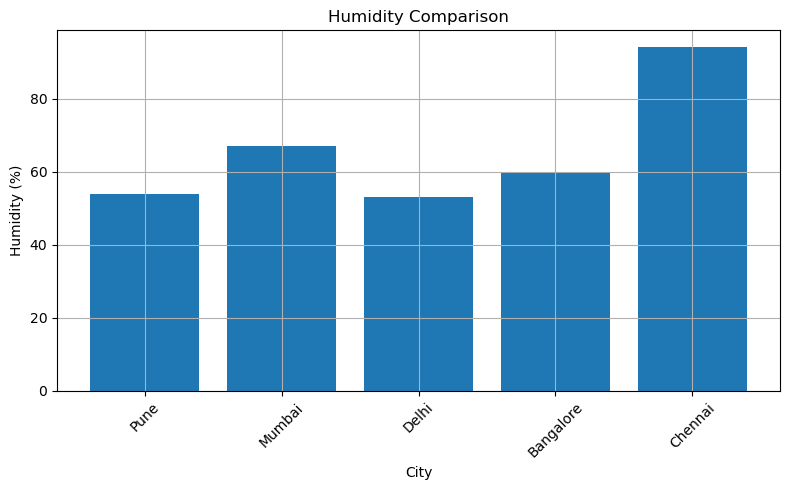

In [5]:
# Humidity visualization
plt.figure(figsize=(8, 5))
plt.bar(df["City"], df["Humidity"])
plt.xlabel("City")
plt.ylabel("Humidity (%)")
plt.title("Humidity Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

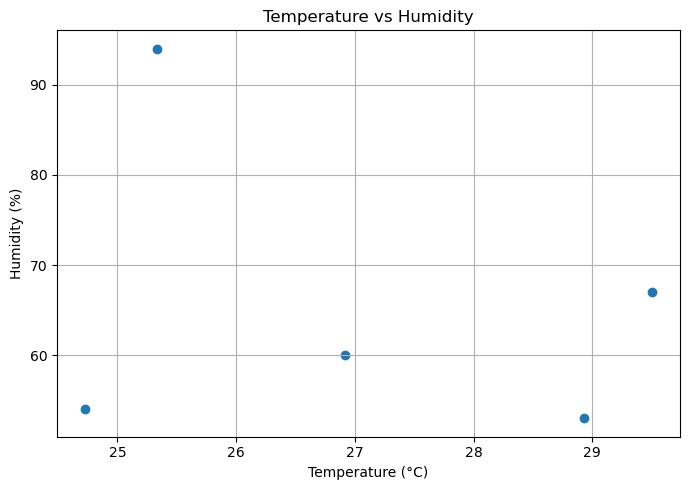

In [6]:
# Temperature vs Humidity
plt.figure(figsize=(7, 5))
plt.scatter(df["Temperature"], df["Humidity"])
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.title("Temperature vs Humidity")
plt.tight_layout()
plt.show()

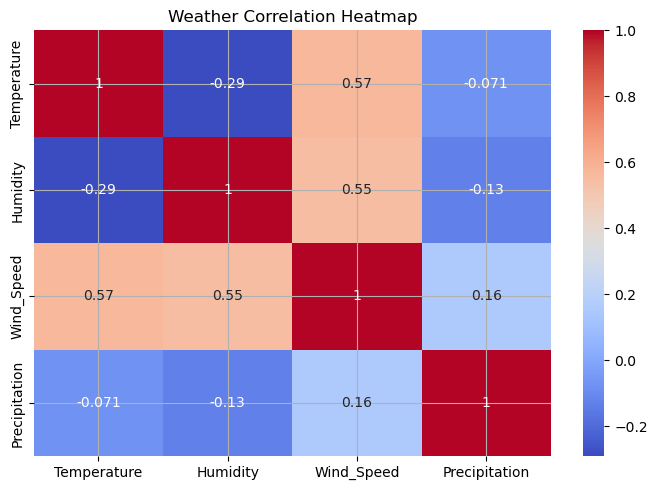

In [7]:
# Correlation
corr = df[["Temperature", "Humidity", "Wind_Speed", "Precipitation"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Weather Correlation Heatmap")
plt.tight_layout()
plt.show()

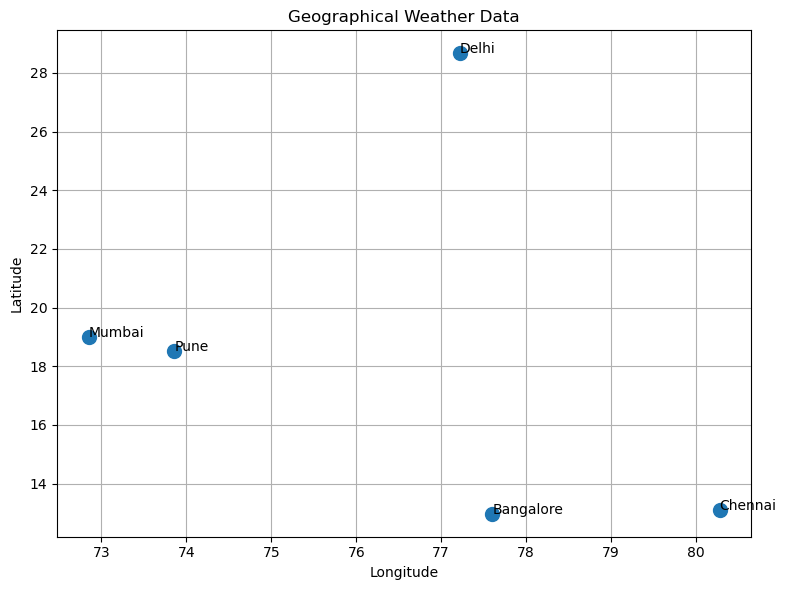

In [8]:
# Geographic visualization
plt.figure(figsize=(8, 6))
plt.scatter(df["Longitude"], df["Latitude"], s=100)

for i in range(len(df)):
    plt.text(df["Longitude"].iloc[i], df["Latitude"].iloc[i], df["City"].iloc[i])

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Weather Data")
plt.tight_layout()
plt.show()